# PlantNet-CNN Optimized

Plant disease classification model notebook.


In [1]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.cm import get_cmap
import random

import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

from tensorflow.keras.models import Sequential
from tensorflow.keras.initializers import GlorotNormal
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization,GlobalAveragePooling2D

from keras.models import load_model
from keras.callbacks import ModelCheckpoint, EarlyStopping
from keras.preprocessing.image import load_img, img_to_array

from sklearn.metrics import confusion_matrix,classification_report

import json

import warnings
warnings.filterwarnings('ignore')


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Data Preprocessing


## Training Image preprocessing

In [3]:
training_set = tf.keras.utils.image_dataset_from_directory(
    '/content/drive/MyDrive/New Plant Diseases Dataset(Augmented)/train',
    labels="inferred",
    label_mode="categorical",
    class_names=None,
    color_mode="rgb",
    batch_size=1024,
    image_size= (224, 224),
    shuffle=True,
    seed=None,
    validation_split=None,
    subset=None,
    interpolation="bilinear",
    follow_links=False,
    crop_to_aspect_ratio=False
)


Found 70299 files belonging to 38 classes.


## validation Image preprocessing

In [4]:
validation_set = tf.keras.utils.image_dataset_from_directory(
    '/content/drive/MyDrive/New Plant Diseases Dataset(Augmented)/valid',
    labels="inferred",
    label_mode="categorical",
    class_names=None,
    color_mode="rgb",
    batch_size=1024,
    image_size= (224, 224),
    shuffle=True,
    seed=None,
    validation_split=None,
    subset=None,
    interpolation="bilinear",
    follow_links=False,
    crop_to_aspect_ratio=False
)

Found 17572 files belonging to 38 classes.


In [5]:
# apply scaling only becouse data already augmented

train_datagen = ImageDataGenerator(rescale=1/255.)
test_datagen = ImageDataGenerator(rescale = 1/255.)




In [6]:
# show how data store
images, labels = next(iter(training_set))
print(f'shape of image is : {images[0].shape}')
print(f'label  \n{labels[0]}')

shape of image is : (224, 224, 3)
label  
[0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


In [7]:
# show all diseases in dataset
train_dir = '/content/drive/MyDrive/New Plant Diseases Dataset(Augmented)/train'

diseases = os.listdir(train_dir)
print(diseases)

['Tomato___Leaf_Mold', 'Tomato___Target_Spot', 'Tomato___Tomato_mosaic_virus', 'Tomato___Late_blight', 'Tomato___Septoria_leaf_spot', 'Tomato___healthy', 'Tomato___Spider_mites Two-spotted_spider_mite', 'Tomato___Tomato_Yellow_Leaf_Curl_Virus', 'Tomato___Early_blight', 'Tomato___Bacterial_spot', 'Potato___Late_blight', 'Squash___Powdery_mildew', 'Strawberry___Leaf_scorch', 'Potato___healthy', 'Strawberry___healthy', 'Potato___Early_blight', 'Pepper,_bell___Bacterial_spot', 'Raspberry___healthy', 'Soybean___healthy', 'Pepper,_bell___healthy', 'Grape___Black_rot', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Corn_(maize)___healthy', 'Corn_(maize)___Common_rust_', 'Orange___Haunglongbing_(Citrus_greening)', 'Corn_(maize)___Northern_Leaf_Blight', 'Grape___Esca_(Black_Measles)', 'Peach___healthy', 'Grape___healthy', 'Peach___Bacterial_spot', 'Apple___Black_rot', 'Cherry_(including_sour)___healthy', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Cherry_(including_sour)___Powdery_mi

In [8]:
# identify uniqe plant in dataset
plants = []
NumberOfDiseases = 0
for plant in diseases:
    if plant.split('___')[0] not in plants:
        plants.append(plant.split('___')[0])
print(f'number of different plants is :{len(plants)}')
print(plants)

number of different plants is :14
['Tomato', 'Potato', 'Squash', 'Strawberry', 'Pepper,_bell', 'Raspberry', 'Soybean', 'Grape', 'Corn_(maize)', 'Orange', 'Peach', 'Apple', 'Cherry_(including_sour)', 'Blueberry']


In [9]:
# identify uniqe plant in dataset
train_dir = '/content/drive/MyDrive/New Plant Diseases Dataset(Augmented)/train'

diseases = [name for name in os.listdir(train_dir) if os.path.isdir(os.path.join(train_dir, name))]

nums = {}
for disease in diseases:
    nums[disease] = len(os.listdir(os.path.join(train_dir, disease)))
img_per_class = pd.DataFrame(nums.values(), index=nums.keys(), columns=["Number of images"])
img_per_class

,Number of images
Tomato___Leaf_Mold,1882
Tomato___Target_Spot,1827
Tomato___Tomato_mosaic_virus,1790
Tomato___Late_blight,1851
Tomato___Septoria_leaf_spot,1745
Tomato___healthy,1926
Tomato___Spider_mites Two-spotted_spider_mite,1741
Tomato___Tomato_Yellow_Leaf_Curl_Virus,1961
Tomato___Early_blight,1920
Tomato___Bacterial_spot,1702


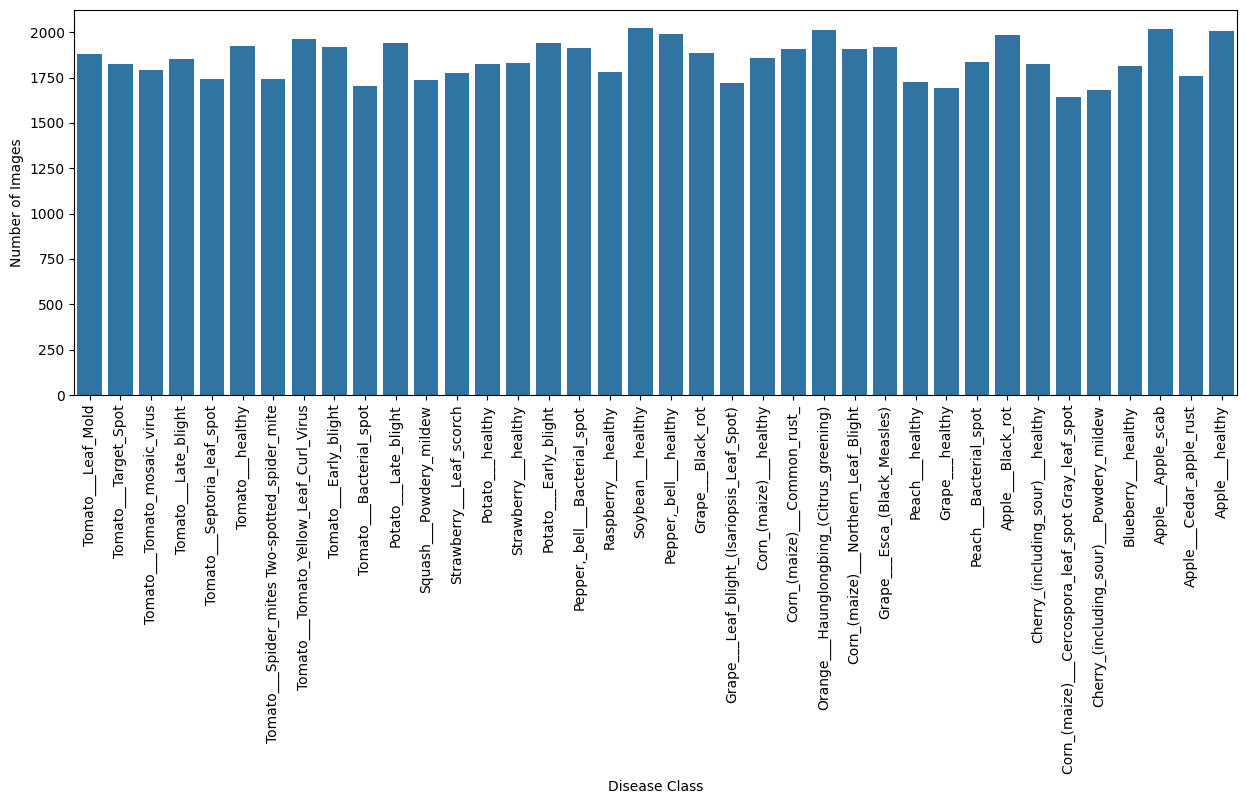

In [10]:
train_dir = '/content/drive/MyDrive/New Plant Diseases Dataset(Augmented)/train'

diseases = [name for name in os.listdir(train_dir) if os.path.isdir(os.path.join(train_dir, name))]

dic = {}
for Class in diseases:
    dic[Class] = len(os.listdir(os.path.join(train_dir, Class)))

df = pd.DataFrame(list(dic.items()), columns=["Disease Class", "Number of Images"])

plt.figure(figsize=(15,5))
sns.barplot(data=df, x='Disease Class', y='Number of Images')
plt.xticks(rotation=90)
plt.show()

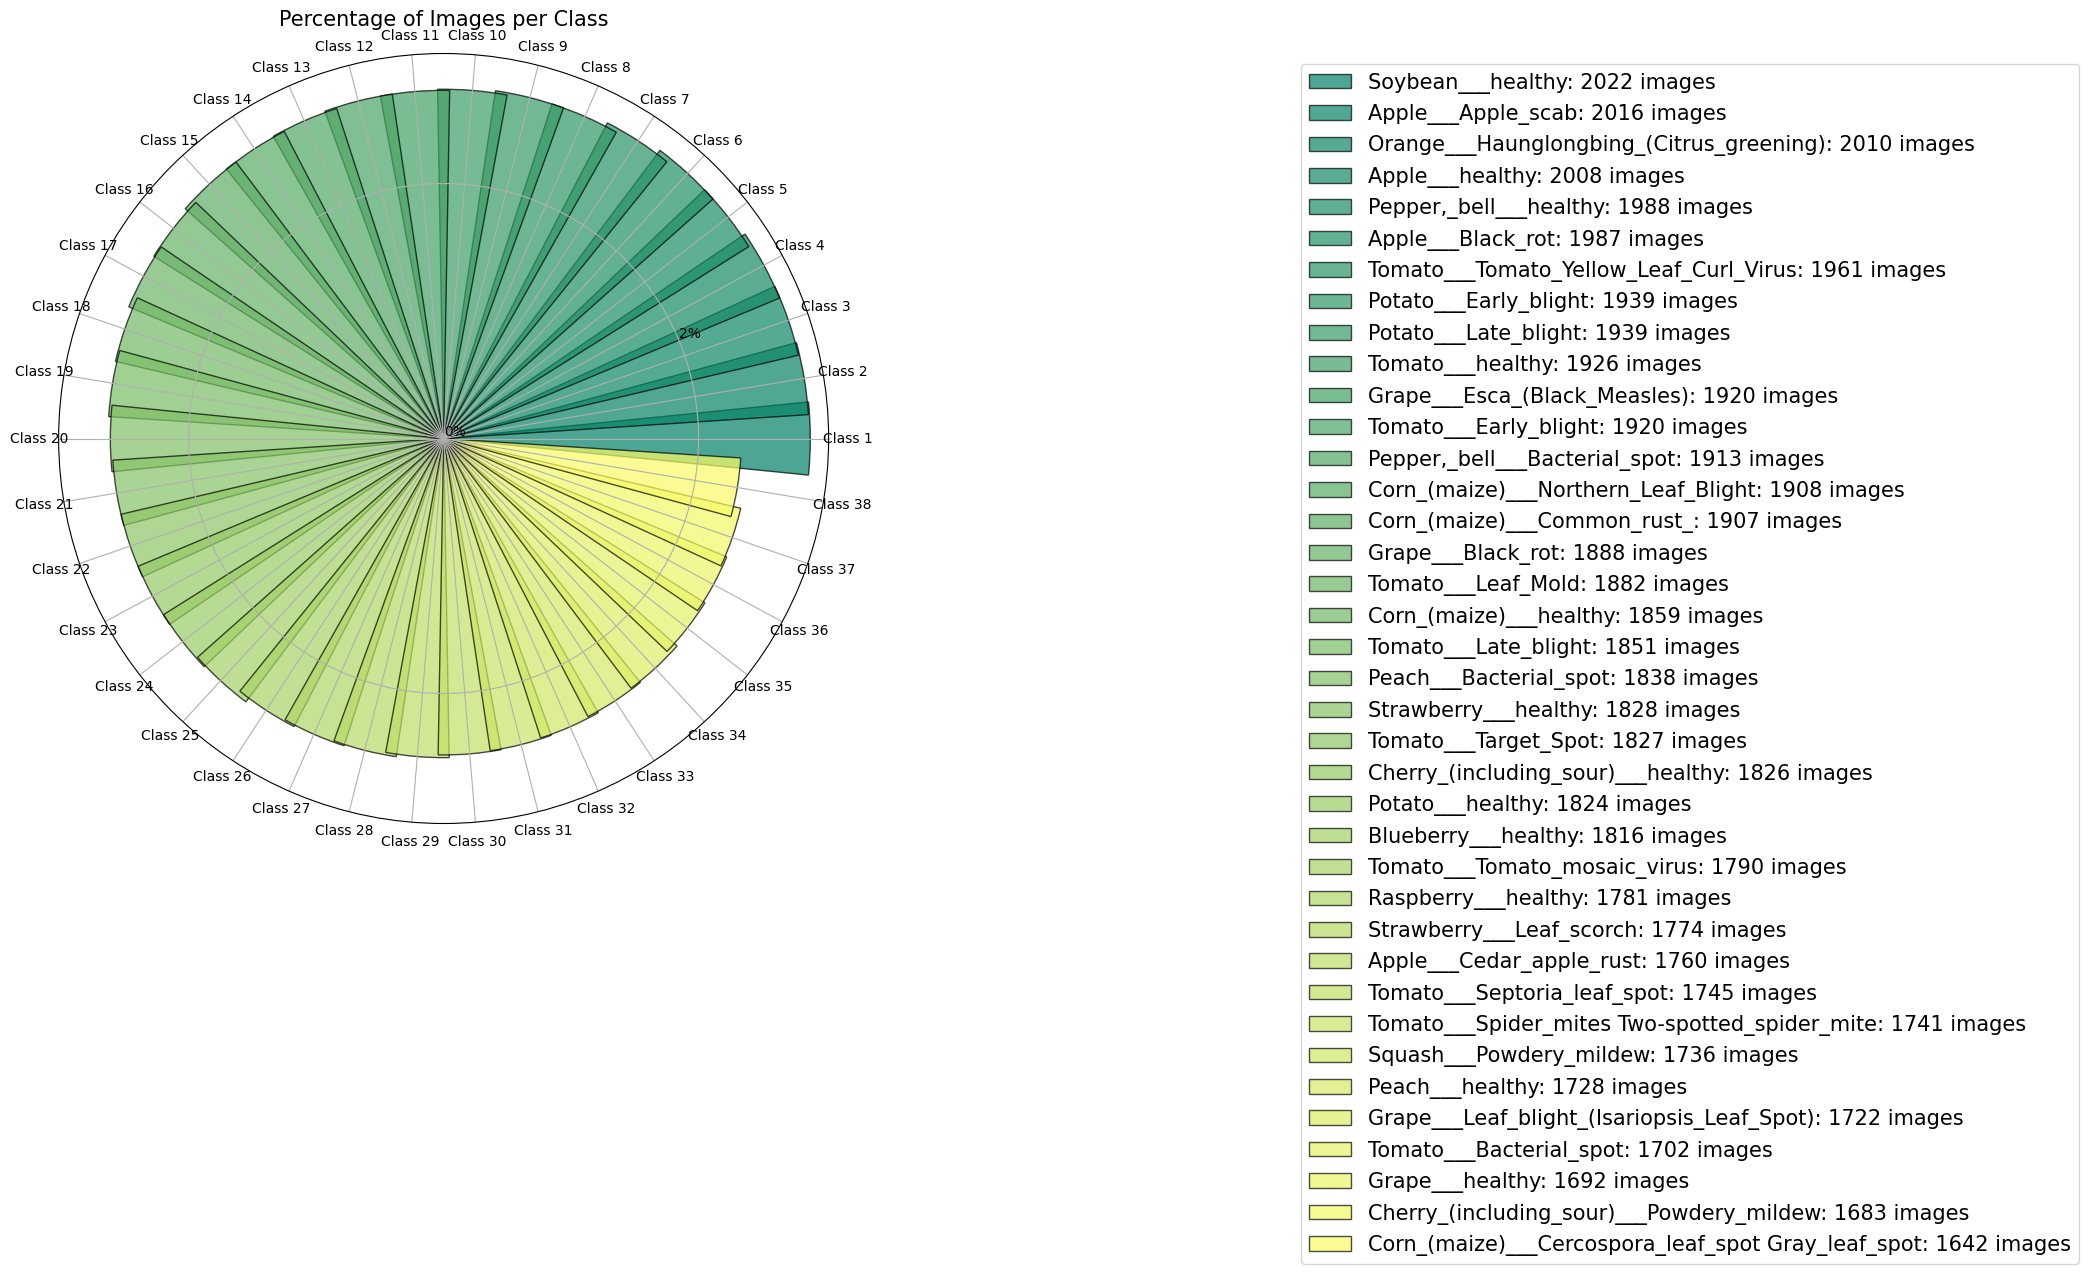

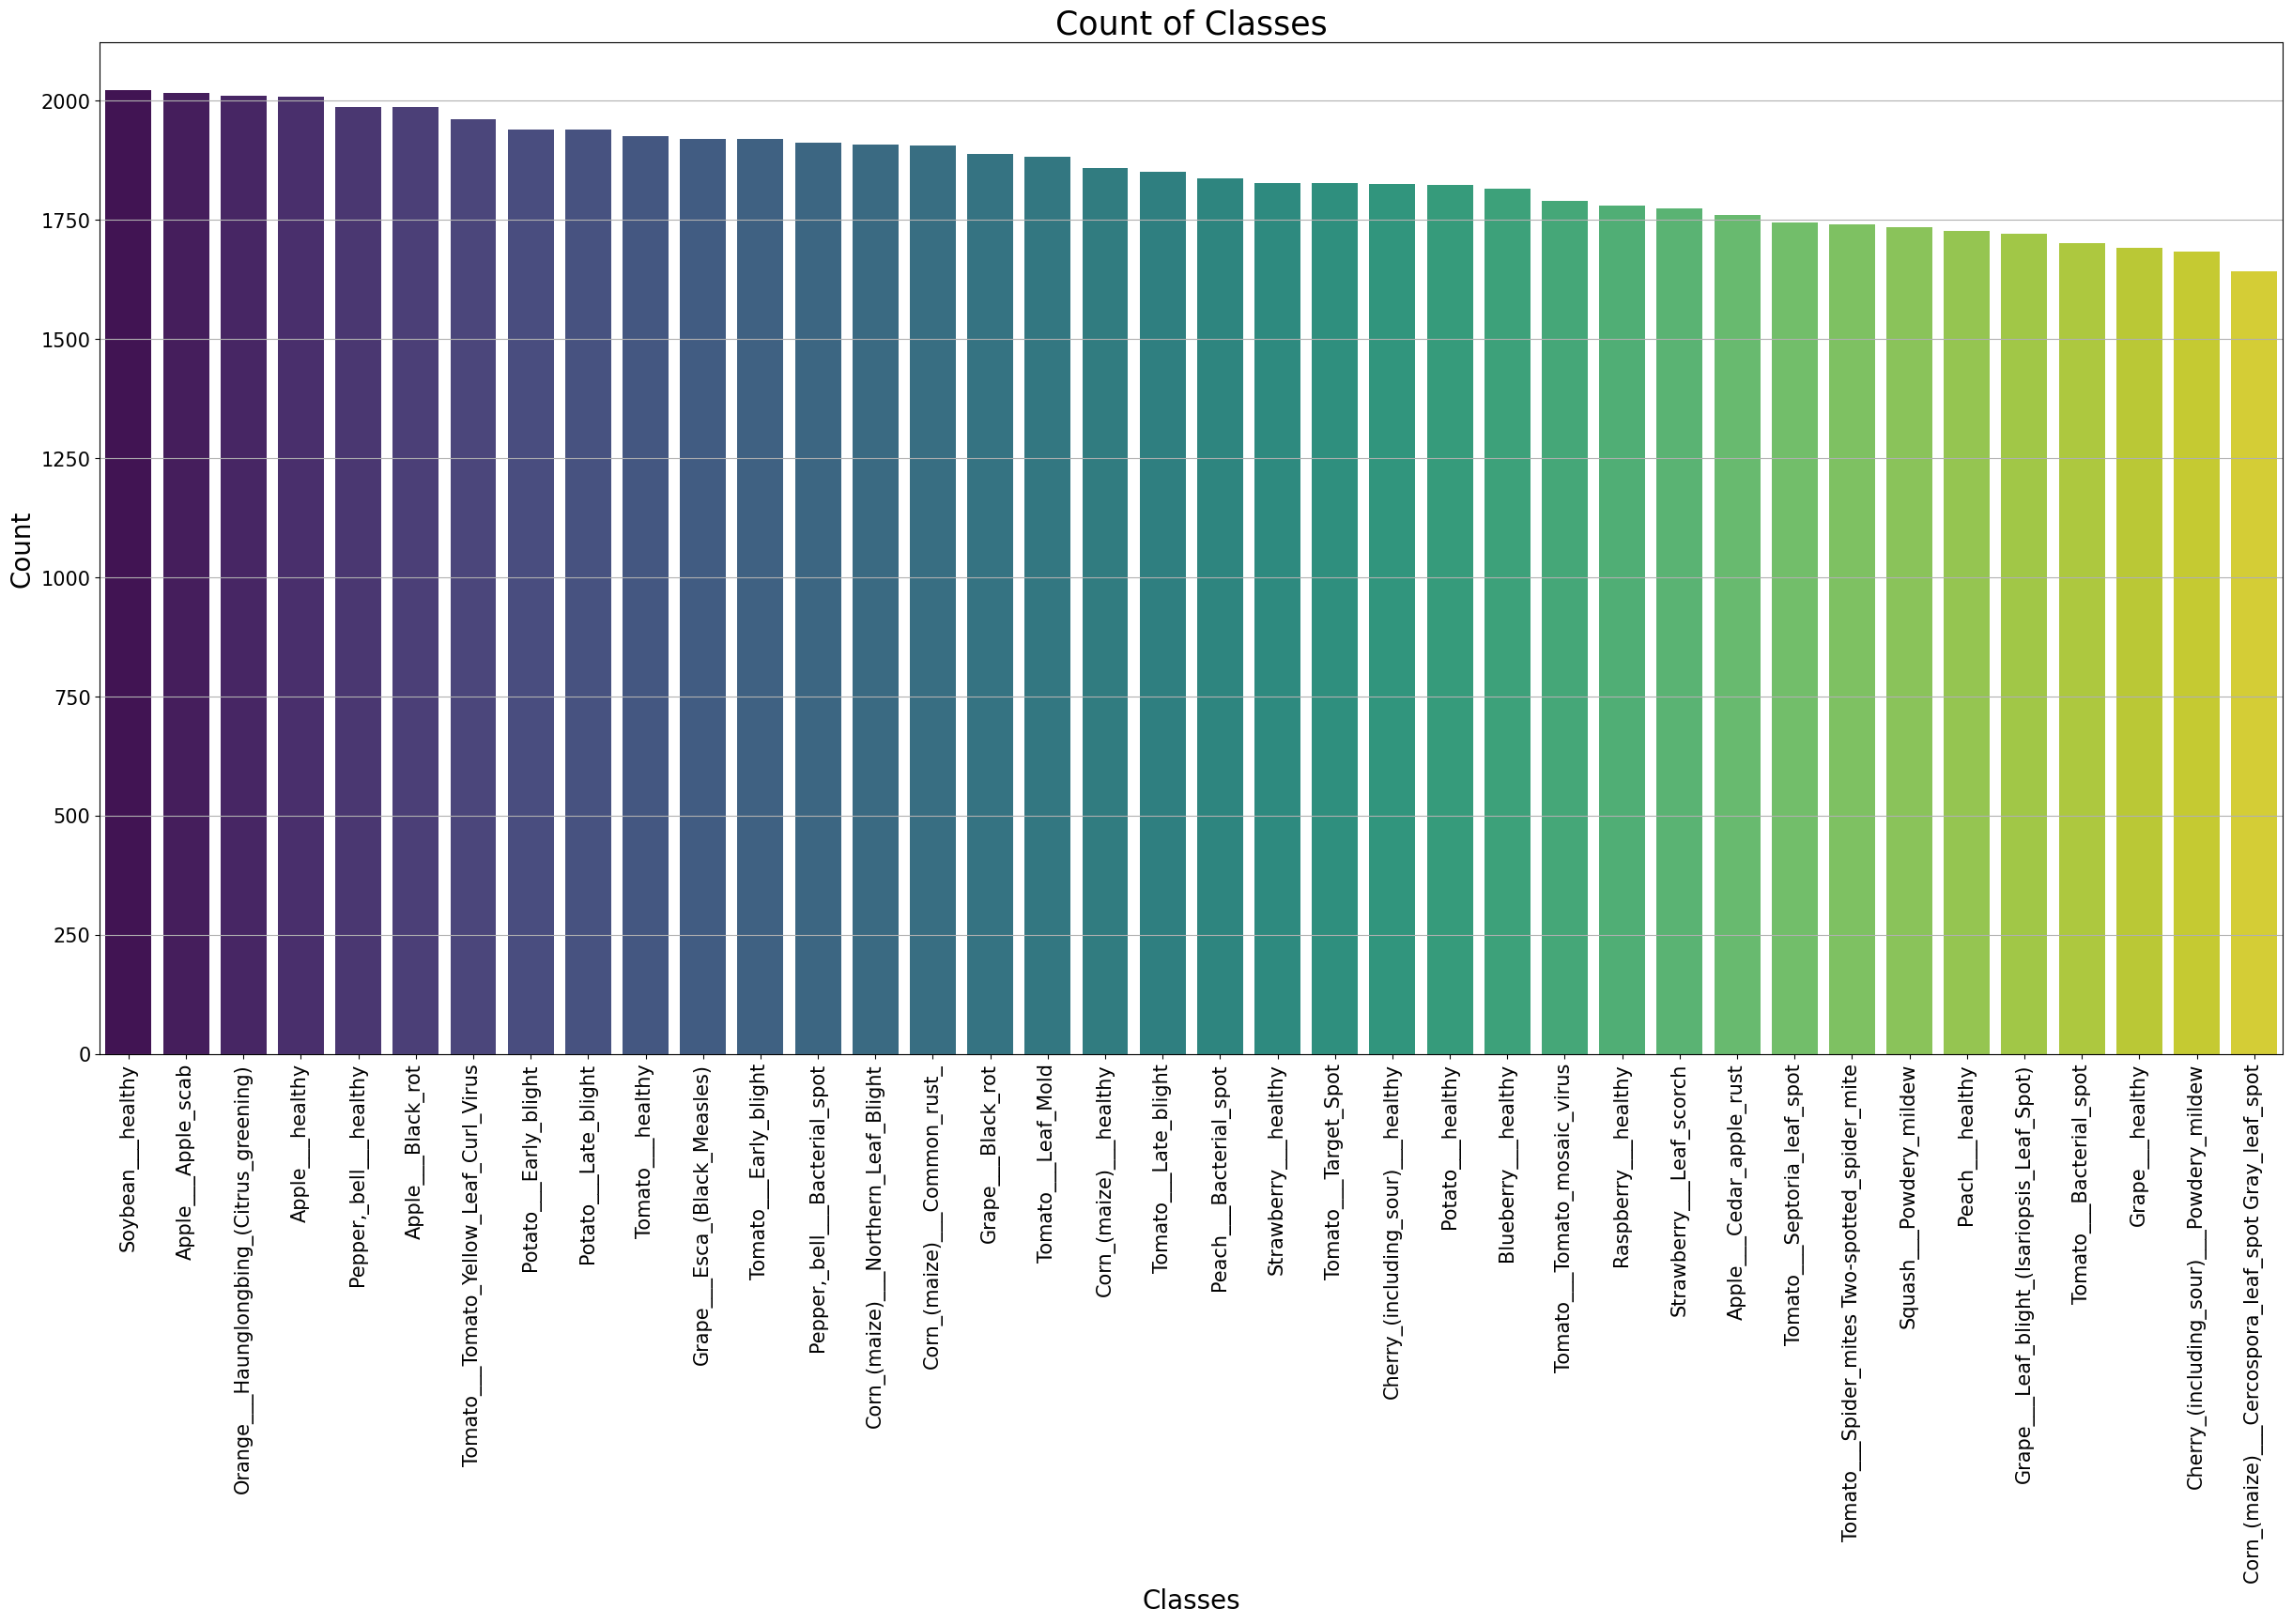

In [11]:
classes = training_set.class_names
base_dir = '/content/drive/MyDrive/New Plant Diseases Dataset(Augmented)/train'

# Counting the number of images in each folder
counts = []
for class_name in classes:
    folder_path = os.path.join(base_dir, class_name)
    counts.append(len([file for file in os.listdir(folder_path) if os.path.isfile(os.path.join(folder_path, file))]))

# Calculating the total number of images
total_count = sum(counts)

# Calculating the percentages
percentages = [(count / total_count) * 100 for count in counts]

# Sort classes, counts, and percentages in descending order
sorted_indices = sorted(range(len(counts)), key=lambda k: counts[k], reverse=True)
classes = [classes[i] for i in sorted_indices]
counts = [counts[i] for i in sorted_indices]
percentages = [percentages[i] for i in sorted_indices]

# Circular Bar Plot
cmap = get_cmap('summer')
angles = np.linspace(0, 2 * np.pi, len(classes), endpoint=False) # Remove duplicate angle
colors = [cmap(i / len(angles)) for i in range(len(angles))]  # Apply colormap
fig, ax = plt.subplots(figsize=(10, 10), subplot_kw={'polar': True})  # Adjust size here
bars = ax.bar(angles, percentages, width=0.2, color=colors, alpha=0.7, edgecolor='black')  # Use colors from colormap

# Add labels
ax.set_xticks(angles)
ax.set_xticklabels([f"Class {i+1}" for i in range(len(classes))], fontsize=10, rotation=90, ha='center')
ax.set_yticks(range(0, int(max(percentages)) + 1, 2))
ax.set_yticklabels([f'{i}%' for i in range(0, int(max(percentages)) + 1, 2)], fontsize=10)
ax.set_title("Percentage of Images per Class", size=15, pad=20)

# Add legend to the right side, showing counts
legend_labels = [f"{class_name}: {count} images" for class_name, count in zip(classes, counts)]
ax.legend(bars, legend_labels, bbox_to_anchor=(1.6, 1), loc='upper left', fontsize=15)

plt.tight_layout()
plt.show()

# Seaborn Bar Plot
plt.figure(figsize=(30, 14))
sns.barplot(x=classes, y=counts, palette="viridis")  # Use folder names as labels

plt.xticks(fontsize=15, rotation=90)
plt.yticks(fontsize=15)
plt.xlabel("Classes", fontsize=20)
plt.ylabel("Count", fontsize=20)
plt.title("Count of Classes", fontsize=25)
plt.grid(axis='y')

plt.show()

In [12]:
# select a specific batch
batch = next(iter(training_set))
images, labels = batch

# select 16 images randomly
indices = random.sample(range(len(images)), 16)
selected_images = np.array([images[i].numpy().astype("uint8") for i in indices])
selected_labels = np.array([labels[i].numpy() for i in indices])

class_names = training_set.class_names

# plotting
plt.figure(figsize=(12, 12))
for i in range(16):
    ax = plt.subplot(4, 4, i + 1)
    plt.imshow(selected_images[i])
    plt.title(class_names[np.argmax(selected_labels[i])])
    plt.axis("off")

plt.tight_layout()
plt.show()

Output hidden; open in https://colab.research.google.com to view.

# Building Model

In [13]:
model = Sequential()

model.add(Conv2D(32,(3,3),activation = 'elu',input_shape=(224,224,3), kernel_initializer=GlorotNormal()))
model.add(Conv2D(32, (3,3), activation='elu', kernel_initializer=GlorotNormal()))
model.add(MaxPooling2D(2,2))

model.add(Conv2D(64, (3,3), activation='elu', kernel_initializer=GlorotNormal()))
model.add(Conv2D(64, (3,3), activation='elu', kernel_initializer=GlorotNormal()))
model.add(MaxPooling2D(2,2))

model.add(Conv2D(128, (3,3), activation='elu', kernel_initializer=GlorotNormal()))
model.add(Conv2D(128, (3,3), activation='elu', kernel_initializer=GlorotNormal()))
model.add(MaxPooling2D(2,2))

# model.add(Flatten())
model.add(GlobalAveragePooling2D())

model.add(Dense(256, activation='elu', kernel_initializer=GlorotNormal()))
model.add(BatchNormalization())
model.add(Dropout(0.2))

model.add(Dense(128, activation='elu', kernel_initializer=GlorotNormal()))
model.add(BatchNormalization())
model.add(Dropout(0.2))

model.add(Dense(64, activation='elu', kernel_initializer=GlorotNormal()))
model.add(BatchNormalization())
model.add(Dropout(0.2))

model.add(Dense(38, activation='softmax'))

model.compile(loss='categorical_crossentropy',optimizer='Adam',metrics=['accuracy'])
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 220, 220, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 110, 110, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 108, 108, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 106, 106, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 53, 53, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 51, 51, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 49, 49, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 24, 24, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 38)             │         2,470 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 365,446 (1.39 MB)

 Trainable params: 364,550 (1.39 MB)

 Non-trainable params: 896 (3.50 KB)

## Compiling and Training Phase

In [14]:
model_checkpoint = ModelCheckpoint('/content/drive/MyDrive/plant_disease_model_checkpoint.h5', monitor='val_accuracy', save_best_only=True, mode='max', verbose=1)
early_stopping = EarlyStopping(monitor='val_accuracy', patience=3, verbose=1, mode='max', restore_best_weights=True)




In [ ]:
history = model.fit(training_set,
                    validation_data=validation_set,
                    epochs=30,
                    batch_size=1024,
                    callbacks=[model_checkpoint, early_stopping])


Epoch 1/30
550/550 ━━━━━━━━━━━━━━━━━━━━ 0s 42s/step - accuracy: 0.3850 - loss: 2.2401 
Epoch 1: val_accuracy improved from -inf to 0.63169, saving model to /content/drive/MyDrive/plant_disease_model_checkpoint.h5


550/550 ━━━━━━━━━━━━━━━━━━━━ 25526s 46s/step - accuracy: 0.3853 - loss: 2.2388 - val_accuracy: 0.6317 - val_loss: 1.2850
Epoch 2/30
415/550 ━━━━━━━━━━━━━━━━━━━━ 1:34:42 42s/step - accuracy: 0.7977 - loss: 0.6727

In [ ]:
def plot_learning_curves(history, save_path=None, color_scheme=('blue', 'orange')):
    plt.figure(figsize=(14, 5))

    # Automatically determine the best epoch based on validation accuracy
    best_epoch = history.history['val_accuracy'].index(max(history.history['val_accuracy'])) + 1

    # Accuracy curve
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], color=color_scheme[0], label='Training Accuracy')
    plt.plot(history.history['val_accuracy'], color=color_scheme[1], linestyle='--', label='Validation Accuracy')
    plt.title('Model Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.xlim(0, best_epoch)
    plt.legend(loc='lower right')
    plt.grid(True, linestyle='--', alpha=0.5)

    # Loss curve
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], color=color_scheme[0], label='Training Loss')
    plt.plot(history.history['val_loss'], color=color_scheme[1], linestyle='--', label='Validation Loss')
    plt.title('Model Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.xlim(0, best_epoch)
    plt.legend(loc='upper right')
    plt.grid(True, linestyle='--', alpha=0.5)

    plt.tight_layout()

     # Save the plot if save_path is provided
    if save_path:
        plt.savefig(save_path, format='png', dpi=300)
        print(f'Plot saved as {save_path}')

    plt.show()



# Display accuracy and loss curves for model history


In [ ]:
plot_learning_curves(history)


In [ ]:
# save model to use later
model.save('plantDiseaseClassification.keras')
